# SwarmRaft: paper analysis notes (11-18)

Working notes on *SwarmRaft: Leveraging Consensus for Robust Drone Swarm Coordination in GNSS-Degraded Environments* (Dev et al., [arXiv:2508.00622](https://arxiv.org/abs/2508.00622)) and its code ([kapeldev/SwarmRaft](https://github.com/kapeldev/SwarmRaft)).

| Part | Topic | Owner | Status |
|---|---|---|---|
| 1 | What the paper tries to solve and the solution it presents, including the setup | Luis | Draft; 1.6 and 1.7 still empty |
| 2 | What we have in the code base, and comparing paper to code | Raphael | Done |
| 3 | Can we make it better? | Dongho | Notes: assumptions, how to tackle each, plan, open question; A1, A2 and A1 + A2 tested (3.5) |

# 1. Describe what the paper is trying to solve & What are the Solution presented by the paper (Including the setup) (Luis)

## 1.1 Related Work/Setting
A Unmanned aerial vehicle (UAV) swarm is a group of drones that work together in a coordinated, autonomous way. In particular, they must maintain accruate and synchronized state information (position, velocity, heading) even in the face of partial failures and environmental interference. (UAV swarms rely heavily on precise coordination, among others, of their positions). To this effect, UAVs are equipped both with Global Navigation Satellite Systems (GNSS) and Inertial Navigation Systems (INS). GNSS signals can be unreliable in real-world conditions, due to dense vegetation, urban canyons or subterranean environments. In addition, GNSS technologies are vulnerable to spoofing or jamming. So, in attempts to make up for these short-comings, UAVs are also equipped with INS systems. These use accelerometer and gyroscope information to estimate the current position of an UAV, given a starting point. One could think of this as moving through a room with the eyes closed. One is at the door, counts how many steps one takes and how often one turns, and hopefully one would have a rough estimate of where one is in the room. Because INS does not rely on external radio signals, it is harder to spoof and can be used in areas where GNSS fails. However, it is less accurate and the accumulation of small errors in pose estimation can cause the estimated position to drift away from its correct one. The limitations of GNSS and INS as standalone systems speak for the use of collaborative, consensus-driven approaches, that combine GNSS, INS and leverage the connections between UAVs in a swarm as a way to achieve a robust and fault-tolerant state estimation for UAV swarms.<br>
System Model: <br>
For this particular paper, we assume the communication graph among the UAVs to be fully connected and synchronous. So every UAV can has a direct link to every other UAV and we assume that the network conditions are such that we don't need to worry about a message that was sent in time step k only being received on time step k+1. The paper does this so it can focus on sensor faults instead of network delays. We also assume that the UAV carries a ranging sensor of the Received Signal Strength Indicator (RSSI) type. This sensor measures the strength of a received signal and by applying a signal propagation model allows a noisy estimation of distance. A lower received signal means the sender is farther away, whilst a higher means it is closer. Walls, obstacles, antenna orientation and the choice of the propagation model all influence the computed distance, so the result is always noisy. RSSI is used in the paper as a way for the UAV's to have some notion of where all other nodes are (also called internode distances). <br>
Messages between nodes are sent over an authenticated broadcast channel protected by pre-distributed cryptographic keys, so message forgery or tampering are detected. <br>
INS can always be relied upon. Only GNSS sensors can be Byzantine (i.e. up to f can fail)


### Operating Conditions:
A UAV swarm is a speciallized case of a distrbitued system, but it can in some ways still be characterized as one. Swarm consensus should: 
* have low-latency agreements
* operate under strict ressource constraints (limited compute/energy resources; intermittent connectivity) / be lightweight
* be robust agains partial system failure
* ensure termination (all non-faulty agents reach a decision)
* ensure agreement (decisions are consistent)
* ensure integrity (decisions are based on valid inputs)

## 1.2 High Level Idea
The paper's key idea was to recognize the commonalities between a swarm and a distributed system, and then adapt a well-established consensus algorithm for distributed systems to our scenario. The used protocol is Raft, usually used for coordination of data storage in databases. More importantly, Raft has a lightweithgt leader architecture and is crash-tolerant. It can recover from network partitions, where some nodes get disconnected from the network for some time and upon reconnecting have to synchronize their storage. The paper adapts the Raft algorithm to enable drones to communicated and synchronize their positions over a network, even in partially GNSS denied environments. When GNSS fails, the swarm uses consensus to reconstruct/verify the location and trajectory of affected nodes based on data they shared and how the affected drones where moving prior to failing. In this way, even when individual drones's sensing mechanisms fail, the swarm remains cohesive. The paper's **SwarmRaft** protocol thus makes use of bothe the GNSS and INS data to produce a robust state estimate to reduce the effects of signal failure, spoofing and sensor drift, with it improving the swarm's situational awareness and operational reliability.

## 1.3 The Workflow
At each time step k, the swarm determines the position of each UAV. To do so, nodes communicate via Raft consensus and elect a leader for that time step. The leader collects every node's position estimate (via GNSS or INS when the other failed) tests to see if the node's reported position is consistent with what the other nodes are seeing, recovers the correct position and sends the results to the nodes. In **SwarmRaft**, so long as n >= 2f + 1 where n is the number of nodes and f the amount of corrupted nodes, the system will be fault tolerant (i.e. if the majority of the nodes is not faulty, the system can recover from incorrectly reported data). <br>
Given a leader for a time step k, the **SwarmRaft** does the following:
1. **SENSE:** Each UAV measures its position (GNSS/INS) and internode distances (each node estimates distance to neighbouring nodes).
2. **INFORM:** Measurements are sent to the leader.
3. **ESTIMATE:** Leader recomputes each UAV's position from range constraints (sanity check).
4. **EVAULUATE:** Leader determines if the received sensor data is faulty or honest based on allowed deviations.
5. **RECOVER:** If sensor data is faulty, that data is replaced with position computed with other drones's estimates.
6. **FINALIZE:** Leader sends final results to all nodes.

## 1.4 Threat Model
Now we will introduce the attack scenarios that **SwarRaft** is prepared to handle.
1. **GNSS Spoofing Attack:** Attacker is able to distort the position measurements of the GNSS of up to f nodes, causing each node to report a position that is offset by some bias. Our inter-node consistency checks and the consensus mechanism ensure that GNSS readings that deviate significantly from the position estimations of other UAVs get detected.
2. **Ranging-Tampering Attack:** Attacker interferes with the RSSI sensors and is able to create errors in the inter-UAV distance measurements. ?????? (Solution part not clear yet)
3. **Collusion Among Faulty Sensors:** Up to f faulty UAVs decide to collude on sensor information. Compromised nodes coordinate their reported measurements and their votes in the **SwarmRaft** protocol, in hopes of influencing the swarm's decision about the position of a particular "victim" node. Due to the majority requirement, the scheme guarantees that you always have a higher number of honest votes than colluding malicious votes, so no coallition (of size <= f) can force an incorrect decision for the whole swarm.

## 1.5 The Algorithm in Depth: Pose Estimation
At each time step k $\in$ $\mathbb{N}$ the UAV i $\in$ {1, ..., n} gets two complementary measurements about its state. The GNSS receiver produces a direct, but noisy (see before) readout of the true position x_(i,k): __formula__ . <br>
The INS computes the estimation of the position based on its previous estimation and increments derived from the gyroscopes and accelerometers's behaviour during the time in between step [k-1, k], called the inertial measurements. <br>

In short: INS has high-rate relative motion at the cost of accumulating drift vs GNSS's drift-free absolute position, but with high instant noise. <br>

The information from the two sensors gets cross-checked and each UAV measures its distance to every other UAV. The reading satisfies the formula: __formula__. This just means that the measured distance is the true distance, offset by the measurement noise of the method. This geometric constraint links the true positions of both drones is used to detect inconsistencies in node's measurements (due to GNSS/INS spoofing or drift).

## 1.6 The Algorithm in Depth: Fault Detection

## 1.7 The Algorithm in Depth: Position Correction and Recovery

# 2. What we have in the code base & Comparing Paper to Code (Raphael)

*To be written.*

# 3. Can we make it better? (Dongho)

## 3.1 What the experiment assumes

- **A1. Ranges are exact.** The code draws ranging noise ($\sigma = 0.5$ m) and then discards it. The vote uses a fixed tolerance of 0.01 m.
- **A2. Honest drones report their exact position.** The code adds no GNSS noise.
- **A3. Each spoofed drone gets its own large offset.** The offset is random, ±30 m per axis. The code does not test one shared offset, or a small offset.
- **A4. Spoofed drones report correct ranges.** The paper lists range tampering as an attack. The code does not test it.
- **A5. Communication is perfect.** The paper assumes a fully connected, synchronous WiFi network. Every report reaches the leader in the same step. The code has no messages and no network.
- **A6. Drones are at random points in a 100 m cube.** The code tests no formation.
- **A7. One static snapshot.** The code has no time steps, no motion and no INS.
- **A8. A leader always exists and is honest.** The paper names Raft. The code has no election and no leader failure.

Also in the code:

- At $n = 2f + 1$, an honest drone gets $f$ votes for and $f$ votes against. The total is 0. The drone stays unflagged only because the rule flags totals below 0.
- The code computes an adaptive recovery threshold and then replaces it with a fixed 3 m.
- The paper gives a calibrated threshold, $T = \mu_e + 3\sigma_e$. The code does not use it.

This list overlaps with part 2. Agree on it with Raphael.

## 3.2 How to tackle each assumption

One change per assumption. We have not tested any of these.

- **A1.** Add ranging noise.
- **A2.** Add GNSS noise to every report.
- **A3.** Use one shared offset for all spoofed drones. Use small offsets.
- **A4.** Let spoofed drones report wrong ranges.
- **A5.** Limit the radio range. Drop some reports.
  - The paper solves only the fully connected case. Every drone reaches every other drone in one hop.
  - A real drone mesh relays messages. A relay can forward a report. It cannot forward a range.
  - Idea: choose the drone with the most links as leader. Compare it with a random leader.
- **A6.** Use formations.
- **A7.** Move the swarm over time.
- **A8.** Simulate Raft election and a leader crash.

## 3.3 Proposed plan

Goal: remove one assumption at a time, measure how the authors' algorithm behaves, and report the result.

1. Start from the reproduction.
2. Test A1 to A5, one at a time.
3. Report three numbers: spoofed drones caught, honest drones wrongly flagged, position error after recovery.

Out of scope for now but if we have time we can also try to try: A6, A7, A8. such A8, we can use knowledge from Social Choice

## 3.4 Open question

Why do some runs fail without noise?

- Source: `notebook.ipynb`, section 4.3. At $n = 17$ without noise, about 3 % of the runs are wrong by metres. The other runs recover the position exactly.
- We do not know the cause. Two candidates: poor geometry of the honest drones, or the start point of the solver (the spoofed position).
- Test: find the failed runs, and compare them with the good runs.

## 3.5 Testing A1 and A2

We add range noise (A1), GNSS noise on every report (A2), and both with the same $\sigma$ (A1 + A2). Everything else is as in the authors' code: $n = 2f + 1$, 1000 runs per point, seed 43.

We test two vote tolerances $\tau$:

- $\tau = 1$ cm, the authors' value.
- $\tau = 3\sigma$ of the pairwise check $\big|\lVert p_A - p_B\rVert - d_{AB}\big|$ for two honest drones, as in the paper's rule $T = \mu_e + 3\sigma_e$. This gives $\tau = 3\sqrt{\sigma_d^2 + 2\sigma_g^2}$, because both reports of a pair contain GNSS noise.

The table shows, at $n = 17$, the fraction of spoofed drones caught and the honest drones moved per run (of 9). It also shows the mean error of the spoofed drones after recovery, which is the paper's metric.

In [1]:
import math
import os

os.environ.setdefault("ENGINE", "docker")  # set before importing runner; "local" only for debugging

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import runner
from runner import run_py, sweep

SIM = "swarmraft_sim.py"
DIAG = [{"n": 2 * f + 1, "f": f} for f in range(1, 9)]  # n = 2f + 1, as in Fig. 2
SIGMAS = [0.1, 0.5, 1.0, 2.0]                          # noise std [m]
AUTHORS_TOL = 0.01                                     # authors' vote tolerance [m]
AUTH, CAL = "τ = 1 cm", "τ = 3σ"
CASES = {"A1": (1, 0), "A2": (0, 1), "A1 + A2": (1, 1)}  # (range noise, GNSS noise)
COLORS = {"A1": "#2a78d6", "A2": "#1baf7a", "A1 + A2": "#52514e"}
FIG = Path("figures")


def calibrated_tol(sd=0.0, sg=0.0):
    # 3 x std of |‖p_A - p_B‖ - d_AB| for two honest drones
    return 3 * math.hypot(sd, math.sqrt(2) * sg)


def noise_params(case, s):
    rng, gnss = CASES[case]
    p = {"noise": s, "apply_noise": True} if rng else {}
    return {**p, "gnss_noise": s} if gnss else p


def run_sim(configs, seed=43, runs=1000):
    # one job per config, cached in results/py/
    return sweep(run_py, [{**c, "runs": runs} for c in configs], seeds=[seed], script=SIM)


pd.Series(runner.environment_info(), name="value").to_frame()

,value
engine,local
python,3.12.16
platform,macOS-27.2.1-arm64-arm-64bit
git_commit,49cf659
git_dirty,True
nix,None
docker,None


In [2]:
base = run_sim(DIAG)  # the authors' code: noise drawn, then discarded
frames = [base.assign(case=case, tol=AUTHORS_TOL) for case in CASES]
for case, (rng, gnss) in CASES.items():
    configs = [{**c, **noise_params(case, s), "tol": t} for c in DIAG for s in SIGMAS
               for t in (AUTHORS_TOL, calibrated_tol(rng * s, gnss * s))]
    frames.append(run_sim(configs).assign(case=case))
runs = pd.concat(frames, ignore_index=True)
runs["sigma"] = runs.gnss_noise.where(runs.case == "A2", runs.noise).fillna(0.0)
runs["tau"] = np.where(runs.tol == AUTHORS_TOL, AUTH, CAL)
runs["caught"] = 1 - runs.spoofed_missed / runs.f

summary = (runs.groupby(["case", "tau", "sigma", "n"])
           .agg(caught=("caught", "mean"), honest_moved=("honest_moved", "mean"), error_m=("err_recovered", "mean"))
           .reset_index())
summary = pd.concat([summary, summary[summary.sigma == 0].assign(tau=CAL)]).sort_values(["case", "tau", "sigma", "n"])

(summary[summary.n == 17]
 .pivot_table(index=["tau", "sigma"], columns="case", values=["caught", "honest_moved", "error_m"])
 .reindex(columns=["caught", "honest_moved", "error_m"], level=0)
 .reindex(columns=list(CASES), level=1)
 .rename(columns={"honest_moved": "honest moved", "error_m": "error [m]"})
 .round(2))

caught               honest moved               error [m]  \
case               A1    A2 A1 + A2           A1    A2 A1 + A2        A1   
tau      sigma                                                             
τ = 1 cm 0.0     1.00  1.00    1.00         0.00  0.00    0.00      0.37   
         0.1     1.00  1.00    1.00         7.04  7.04    7.04      6.09   
         0.5     1.00  1.00    1.00         7.22  7.28    7.38      6.38   
         1.0     1.00  1.00    1.00         7.48  7.71    7.86      6.69   
         2.0     1.00  1.00    1.00         7.89  8.32    8.40      7.30   
τ = 3σ   0.0     1.00  1.00    1.00         0.00  0.00    0.00      0.37   
         0.1     1.00  1.00    1.00         0.00  0.00    0.00      0.49   
         0.5     1.00  1.00    1.00         0.00  0.00    0.00      0.94   
         1.0     1.00  0.99    0.97         0.00  0.03    0.03      1.57   
         2.0     0.95  0.85    0.73         0.01  0.01    0.00      3.44   

                              
case              A2 A1 + A2  
tau      sigma                
τ = 1 cm 0.0    0.37    0.37  
         0.1    6.12    6.13  
         0.5    6.36    6.48  
         1.0    6.64    6.88  
         2.0    7.05    7.64  
τ = 3σ   0.0    0.37    0.37  
         0.1    0.46    0.51  
         0.5    0.95    1.21  
         1.0    1.75    2.50  
         2.0    5.96    9.60

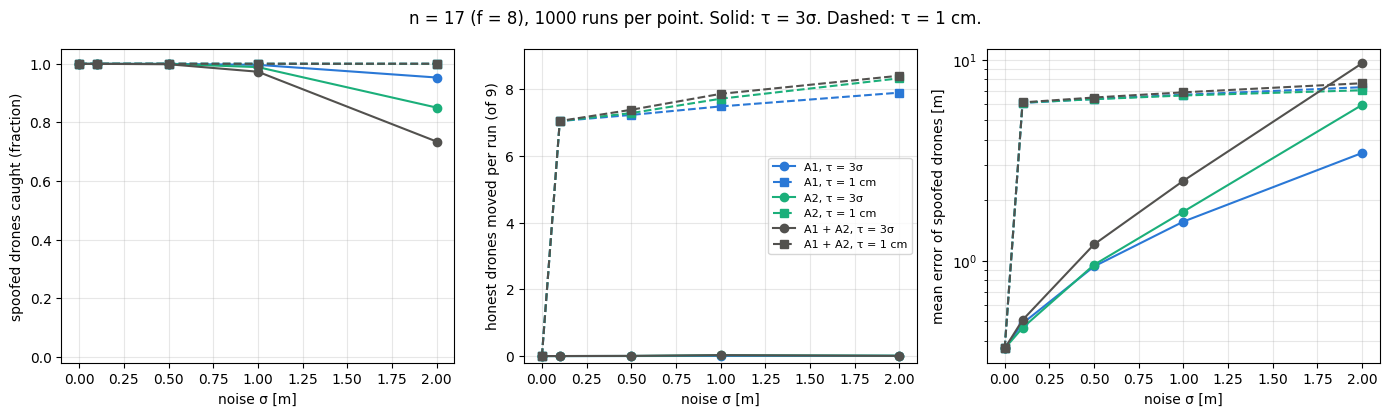

In [3]:
s17 = summary[summary.n == 17]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for case, tau in [(case, tau) for case in CASES for tau in (CAL, AUTH)]:
    g = s17[(s17.case == case) & (s17.tau == tau)]
    for ax, col in zip(axes, ("caught", "honest_moved", "error_m")):
        ax.plot(g.sigma, g[col], "o-" if tau == CAL else "s--", c=COLORS[case], label=f"{case}, {tau}")
axes[0].set(ylabel="spoofed drones caught (fraction)", ylim=(-0.02, 1.05))
axes[1].set(ylabel="honest drones moved per run (of 9)", ylim=(-0.2, 9.2))
axes[2].set(ylabel="mean error of spoofed drones [m]", yscale="log")
for ax in axes:
    ax.set(xlabel="noise σ [m]")
    ax.grid(alpha=0.3, which="both")
axes[1].legend(fontsize=8)
fig.suptitle("n = 17 (f = 8), 1000 runs per point. Solid: τ = 3σ. Dashed: τ = 1 cm.")
fig.tight_layout()
fig.savefig(FIG / "noise_a1_a2.pdf", bbox_inches="tight")

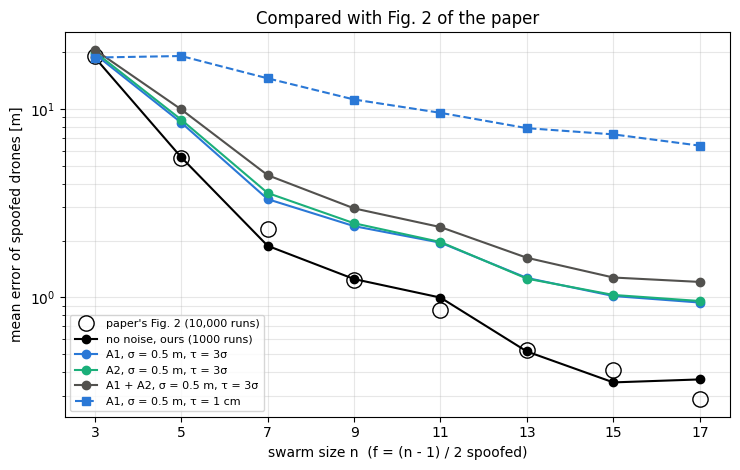

In [4]:
paper = pd.Series(np.load("sim/swarmraft/avg_errors.npy"), index=np.load("sim/swarmraft/ns.npy"))
ref = summary[(summary.case == "A1") & (summary.tau == AUTH) & (summary.sigma == 0)]
s05 = summary[summary.sigma == 0.5]

fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.plot(paper.index, paper.values, "o", mfc="none", mec="black", ms=11, label="paper's Fig. 2 (10,000 runs)")
ax.plot(ref.n, ref.error_m, "o-", c="black", label="no noise, ours (1000 runs)")
for case, c in COLORS.items():
    g = s05[(s05.case == case) & (s05.tau == CAL)]
    ax.plot(g.n, g.error_m, "o-", c=c, label=f"{case}, σ = 0.5 m, τ = 3σ")
g = s05[(s05.case == "A1") & (s05.tau == AUTH)]
ax.plot(g.n, g.error_m, "s--", c=COLORS["A1"], label="A1, σ = 0.5 m, τ = 1 cm")
ax.set(yscale="log", xticks=paper.index, xlabel="swarm size n  (f = (n - 1) / 2 spoofed)",
       ylabel="mean error of spoofed drones [m]", title="Compared with Fig. 2 of the paper")
ax.grid(alpha=0.3, which="both")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "noise_vs_fig2.pdf", bbox_inches="tight")

**Result** at $n = 17$.

- $\tau = 1$ cm fails in all three cases, also at $\sigma = 0.1$ m. Each run moves 7.0 to 8.4 of 9 honest drones, and the error is 6.1 to 7.6 m instead of 0.37 m.
- $\tau = 3\sigma$ moves at most 0.03 honest drones per run. Up to $\sigma = 1$ m it catches at least 97 % of the spoofed drones. At $\sigma = 0.5$ m the error is 0.94 m (A1), 0.95 m (A2) and 1.21 m (A1 + A2).
- From $\sigma = 1$ m, GNSS noise causes more error than range noise (1.75 against 1.57 m at 1 m).
- At $\sigma = 2$ m the wide $\tau$ lets spoofed drones through. The scheme misses 5 % of them for A1, 15 % for A2 and 27 % for A1 + A2. A1 + A2 then has an error of 9.6 m. This is worse than with $\tau = 1$ cm (7.6 m).
- Our noise-free run matches Fig. 2, because it uses the first 1000 of the authors' 10,000 runs. With $\tau = 3\sigma$ the curve keeps its shape but moves up. With $\tau = 1$ cm it falls only from 19 m to 6.4 m.

The scheme copes with noise only when $\tau$ fits the noise level. The paper gives no noise level, and the code uses 1 cm.

Limits:

- We use 1000 runs per point. At $n = 17$, a difference of less than about 0.1 m can come from the run count alone (0.37 m here, 0.29 m with 10,000 runs).
- The noise is Gaussian and independent for each drone and pair. Nearby drones have correlated GNSS errors in reality, and the pairwise check removes part of a common error. We did not test this.
- $\tau$ uses the true $\sigma$. A real swarm must estimate it.